### Top 3 genres (All Artist & Popularity Filter) - @Gebra 
    * Genre-year trend to ensure genre popularity not declining = song count + avg. popularity



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Import data from ironhack_idol_df.csv
df = pd.read_csv('../data/clean/ironhack_idol_df.csv')
print(f"Number of rows before: {len(df)}")

# 2. Release date filtering
df_from_2016 = df[df['album_release_year'] >= 2016].copy()
print(f"Number of rows after filtering (since 2016): {len(df_from_2016)}")

# 3. filtering: arist, who has at least 3 song
artist_track_counts = df_from_2016.groupby('artist_name')['track_id'].transform('count')
df_filtered = df_from_2016[artist_track_counts >= 3].copy()

display(df_filtered)

print(f"Number of rows after filtering (artists with >= 3 tracks): {len(df_filtered)}")
print("\n" + "="*60 + "\n")

# 4. Grouping by year and main genre (main_genre)
# Calculate the average song popularity, artist popularity, and the count of items
genre_yearly_trends = df_filtered.groupby(['album_release_year', 'main_genre']).agg(
    avg_track_popularity=('track_popularity', 'mean'),
    avg_artist_popularity=('artist_popularity', 'mean'),
    track_count=('track_id', 'count')
).reset_index()

# 5. Creating pivot tables for an overview (Columns: Years, Rows: Genres)
# A) Track Popularity trends
track_pop_pivot = genre_yearly_trends.pivot(
    index='main_genre', 
    columns='album_release_year', 
    values='avg_track_popularity'
).round(2).sort_values(by=2016, ascending=False)

# B) Artist Popularity trends
artist_pop_pivot = genre_yearly_trends.pivot(
    index='main_genre', 
    columns='album_release_year', 
    values='avg_artist_popularity'
).round(2).sort_values(by=2016, ascending=False)

# 6. Display results
print("Yearly trends: Average TRACK Popularity\n")
display(track_pop_pivot)

print("\n" + "="*60 + "\n")

print("Yearly trends: Average ARTIST Popularity\n")
display(artist_pop_pivot)


Number of rows before: 5263
Number of rows after filtering (since 2016): 5263


,track_id,track_name,track_popularity,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_total_tracks,album_type,track_duration_min,album_release_year,main_genre
1,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),63,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),26,album,3.755467,2021,pop
2,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,72,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,16,album,2.641050,2021,pop
3,41zXlQxzTi6cGAjpOXyLYH,idontwannabeyouanymore,78,Billie Eilish,90.0,118692183.0,[],7fRrTyKvE4Skh93v97gtcU,dont smile at me,9,single,3.392817,2017,pop
4,13jRFAGT8qd6aBwtJySlUm,Allein Allein - BENNETT Remix,52,Alok,76.0,11247155.0,"['brazilian bass', 'electronic', 'slap house',...",1WKoDELzbFRR6UWNGh50LO,Allein Allein (feat. FREY) [BENNETT Remix],2,single,2.432950,2024,electronic / edm
6,3LtpKP5abr2qqjunvjlX5i,Doja,77,Central Cee,79.0,9666661.0,"['uk drill', 'drill', 'uk grime', 'grime']",6oECjagksATHu2UaclXrq1,Doja,1,single,1.623200,2022,hip-hop / rap
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5257,1qBXkDmnMZXaumaaxwmdYu,First Day At School,39,Carlos Rafael Rivera,48.0,20284.0,[],7Gdn94u4xTxoIpfq2rZci9,The Queen's Gambit (Music from the Netflix Lim...,38,album,1.215117,2020,classical / instrumental
5258,4y4spB9m0Q6026KfkAvy9Q,Lonely (with benny blanco),66,Justin Bieber,91.0,85050158.0,[],3P5WIUJO0Ots1lQx09TOxk,Lonely (with benny blanco),1,single,2.488283,2020,pop
5259,6GFrELGVKBXRcrTNkwjSfF,Body And Mind,54,girl in red,73.0,8771418.0,['bedroom pop'],69p42ovQdwmYPLUsAQpeNn,if i could make it go quiet,11,album,3.111200,2021,pop
5260,58VTP6KnZs12PcAj5rMJ4W,the fruits,65,Paris Paloma,66.0,786890.0,[],48ssTnnFOCIP17sRaFNqu1,the fruits,1,single,3.494967,2022,indie / alternative


Number of rows after filtering (artists with >= 3 tracks): 3658


Yearly trends: Average TRACK Popularity



album_release_year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
main_genre,,,,,,,,,,
rock / metal,63.25,46.92,55.11,5.00,35.67,41.50,36.86,59.68,47.00,55.00
electronic / edm,62.90,59.44,57.29,55.32,44.57,55.57,54.00,48.00,43.95,44.03
r&b / soul,61.33,61.83,65.00,56.75,52.23,51.13,62.62,58.78,53.98,57.89
country,56.73,68.00,67.25,47.50,40.67,53.50,39.67,50.00,NaN,52.21
indie / alternative,56.20,57.83,52.02,57.00,49.50,53.20,46.62,55.24,59.62,73.00
hip-hop / rap,55.86,56.52,64.99,56.38,62.53,51.94,63.47,66.11,56.17,53.76
pop,54.85,51.74,58.91,60.92,58.41,62.81,56.77,55.64,67.82,70.60
niche / unknown,44.33,43.00,31.88,31.17,36.25,28.67,32.00,36.44,36.90,35.84
soundtrack,32.27,34.84,35.20,35.92,45.20,35.17,29.83,46.60,48.50,46.33




Yearly trends: Average ARTIST Popularity



album_release_year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
main_genre,,,,,,,,,,
hip-hop / rap,88.78,81.10,85.85,79.22,82.82,80.44,81.00,88.51,79.31,63.42
r&b / soul,87.60,79.00,77.76,79.00,78.36,82.97,79.58,73.59,67.60,72.32
pop,82.50,86.74,79.98,80.47,85.57,87.56,82.17,81.95,84.80,83.63
electronic / edm,77.70,78.92,77.43,75.09,74.36,71.29,71.81,67.68,60.67,59.47
indie / alternative,74.40,73.92,73.51,75.54,74.30,78.67,69.52,72.28,73.81,80.50
country,68.91,78.50,67.50,70.25,73.33,65.50,67.33,86.33,NaN,55.90
rock / metal,68.50,75.23,69.44,73.00,65.47,72.70,57.14,76.00,71.67,71.00
soundtrack,64.60,60.53,57.60,56.88,51.80,53.50,55.42,57.40,72.25,68.00
niche / unknown,58.50,51.40,51.88,38.83,43.50,36.33,39.88,46.78,46.08,36.20


<Figure size 1200x600 with 0 Axes>

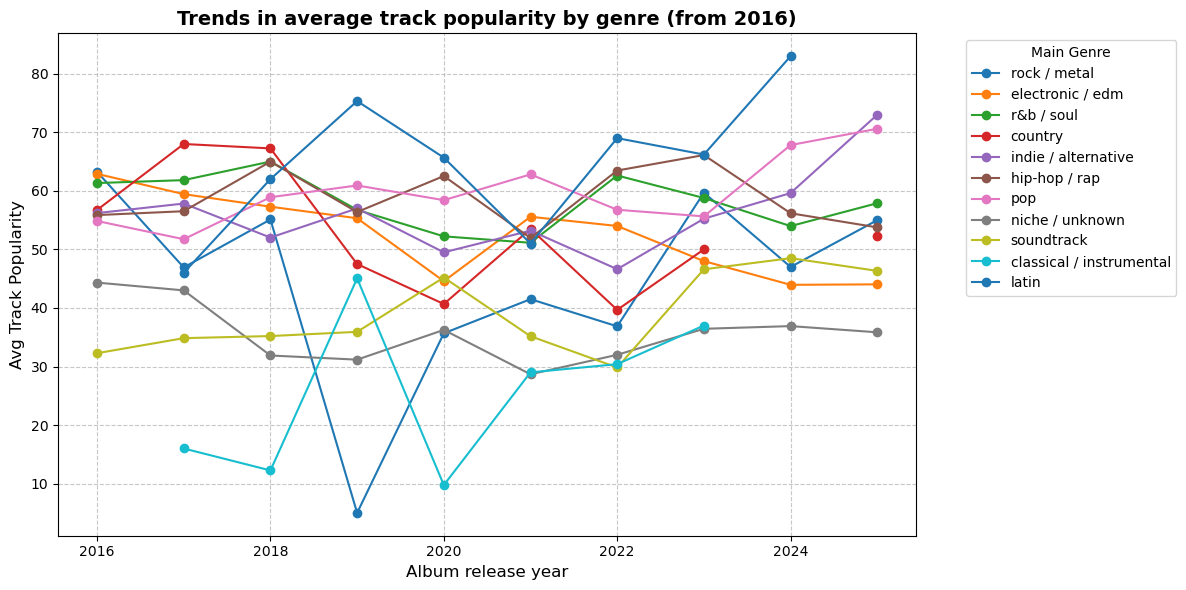

<Figure size 1200x600 with 0 Axes>

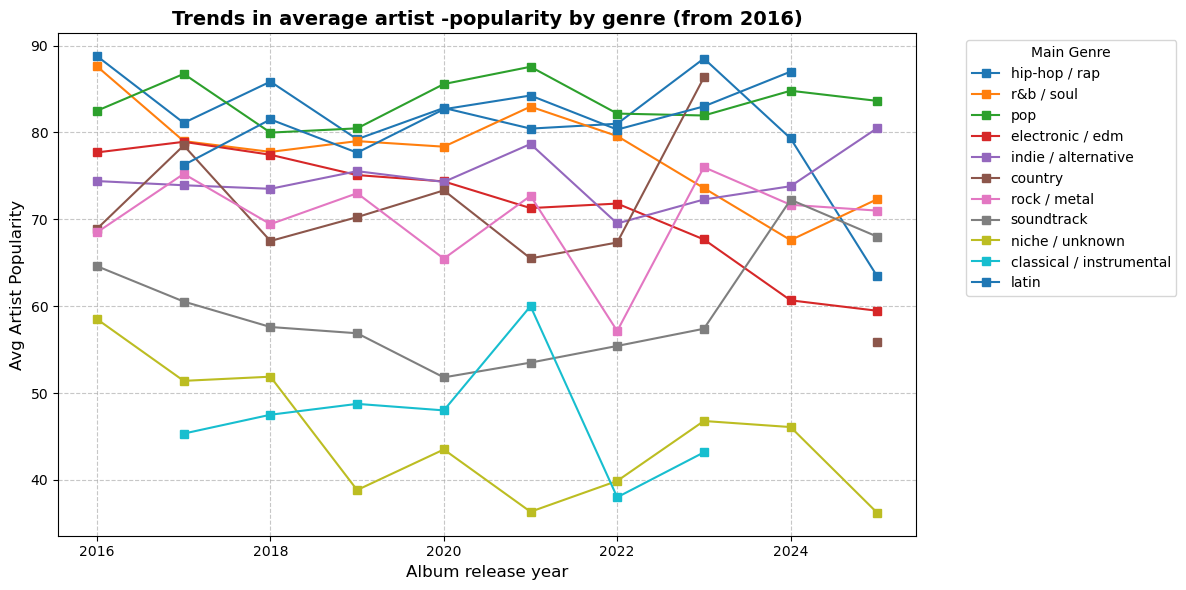

In [2]:
# ==========================================
# 7. CREATING LINE CHARTS (PLOTS)
# ==========================================

# A) Track Popularity line chart
plt.figure(figsize=(12, 6))
# Transpose the pivot - swap the rows and columns using .T so that the years appear on the X-axis.
track_pop_pivot.T.plot(kind='line', marker='o', figsize=(12, 6))

plt.title('Trends in average track popularity by genre (from 2016)', fontsize=14, fontweight='bold')
plt.xlabel('Album release year', fontsize=12)
plt.ylabel('Avg Track Popularity', fontsize=12)
plt.legend(title='Main Genre', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# B) Artist Popularity line chart
plt.figure(figsize=(12, 6))
artist_pop_pivot.T.plot(kind='line', marker='s', figsize=(12, 6))

plt.title('Trends in average artist -popularity by genre (from 2016)', fontsize=14, fontweight='bold')
plt.xlabel('Album release year', fontsize=12)
plt.ylabel('Avg Artist Popularity', fontsize=12)
plt.legend(title='Main Genre', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Number of filtered rows (2016+ and selected genres): 3194
------------------------------------------------------------
YEARLY TRENDS: Average Track Popularity (filtered)


album_release_year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
main_genre,,,,,,,,,,
electronic / edm,62.90,59.44,57.29,55.32,44.57,55.57,54.00,48.00,43.95,44.03
r&b / soul,61.33,61.83,65.00,56.75,52.23,51.13,62.62,58.78,53.98,57.89
country,56.73,68.00,67.25,47.50,40.67,53.50,39.67,50.00,NaN,52.21
indie / alternative,56.20,57.83,52.02,57.00,49.50,53.20,46.62,55.24,59.62,73.00
hip-hop / rap,55.86,56.52,64.99,56.38,62.53,51.94,63.47,66.11,56.17,53.76
pop,54.85,51.74,58.91,60.92,58.41,62.81,56.77,55.64,67.82,70.60




YEARLY TRENDS: Average Artist Popularity (filtered)


album_release_year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
main_genre,,,,,,,,,,
hip-hop / rap,88.78,81.10,85.85,79.22,82.82,80.44,81.00,88.51,79.31,63.42
r&b / soul,87.60,79.00,77.76,79.00,78.36,82.97,79.58,73.59,67.60,72.32
pop,82.50,86.74,79.98,80.47,85.57,87.56,82.17,81.95,84.80,83.63
electronic / edm,77.70,78.92,77.43,75.09,74.36,71.29,71.81,67.68,60.67,59.47
indie / alternative,74.40,73.92,73.51,75.54,74.30,78.67,69.52,72.28,73.81,80.50
country,68.91,78.50,67.50,70.25,73.33,65.50,67.33,86.33,NaN,55.90


<Figure size 1000x500 with 0 Axes>

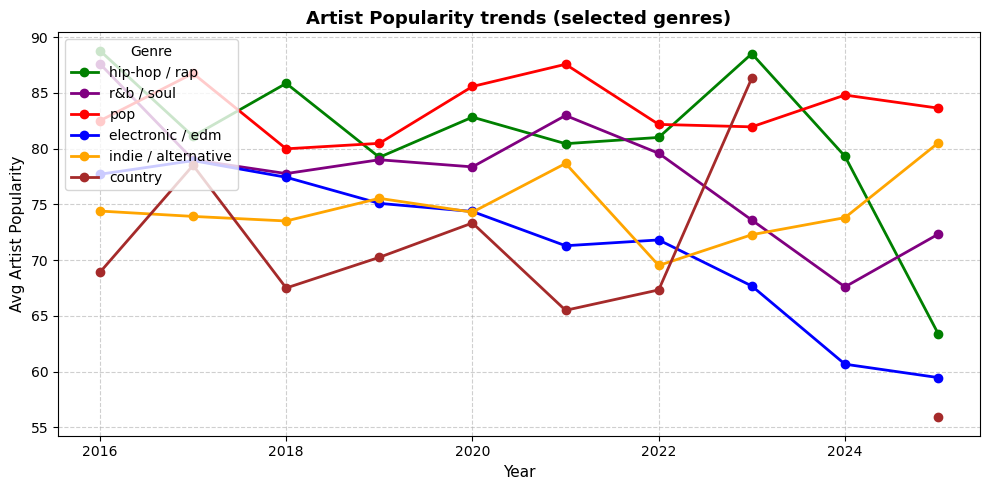

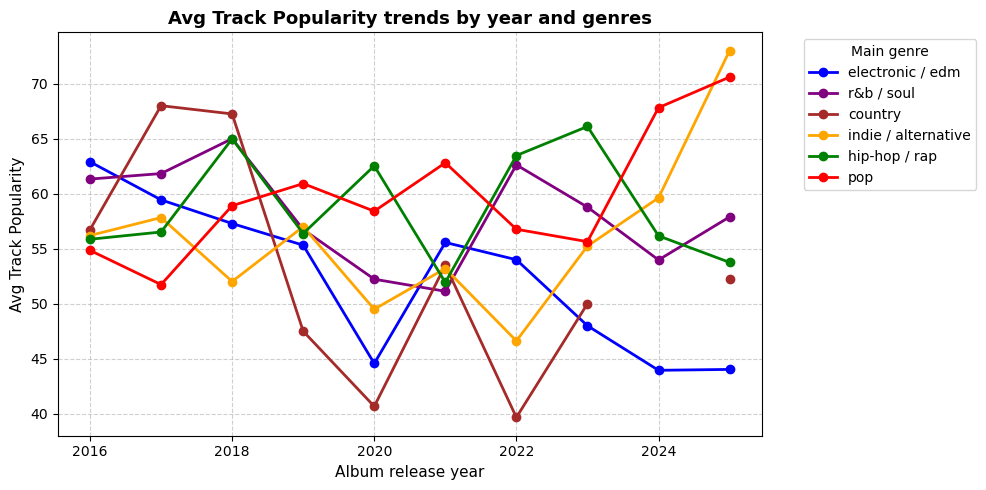

In [6]:
# ==========================================
# 8. GROUPING AND PIVOT TABLES
# ==========================================

target_genres = ['electronic / edm','pop','hip-hop / rap','r&b / soul','indie / alternative','country']
df_filtered = df_filtered[df_filtered['main_genre'].isin(target_genres)].copy()

print(f"Number of filtered rows (2016+ and selected genres): {len(df_filtered)}")
print("-" * 60)


genre_yearly_trends = df_filtered.groupby(['album_release_year', 'main_genre']).agg(
    avg_track_popularity=('track_popularity', 'mean'),
    avg_artist_popularity=('artist_popularity', 'mean'),
    track_count=('track_id', 'count')
).reset_index()

track_pop_pivot = genre_yearly_trends.pivot(
    index='main_genre', 
    columns='album_release_year', 
    values='avg_track_popularity'
).round(2).sort_values(by=2016, ascending=False)

artist_pop_pivot = genre_yearly_trends.pivot(
    index='main_genre', 
    columns='album_release_year', 
    values='avg_artist_popularity'
).round(2).sort_values(by=2016, ascending=False)

# Display results
print("YEARLY TRENDS: Average Track Popularity (filtered)")
display(track_pop_pivot)

print("\n" + "="*60 + "\n")

print("YEARLY TRENDS: Average Artist Popularity (filtered)")
display(artist_pop_pivot)


# ==========================================
# 9. EXTRA DIAGRAMS
# ==========================================

# Chart colors
genre_colors = {
    'electronic / edm': 'blue',
    'pop': 'red',
    'hip-hop / rap': 'green',
    'r&b / soul': 'purple',
    'indie / alternative': 'orange',
    'country': 'brown'
}

# A) Line chart for artist popularity (only the 3 selected genres)
plt.figure(figsize=(10, 5))
artist_pop_pivot.T.plot(kind='line', marker='o', linewidth=2, figsize=(10, 5), color=[genre_colors[genre] for genre in artist_pop_pivot.index])
plt.title('Artist Popularity trends (selected genres)', fontsize=13, fontweight='bold')
plt.xlabel('Year', fontsize=11)
plt.ylabel('Avg Artist Popularity', fontsize=11)
plt.legend(title='Genre', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# B) Extra: Line chart – Annual comparison based on song popularity
track_pop_pivot.T.plot(kind='line', marker='o', linewidth=2, figsize=(10, 5), color=[genre_colors[genre] for genre in track_pop_pivot.index])

plt.title('Avg Track Popularity trends by year and genres', fontsize=13, fontweight='bold')
plt.xlabel('Album release year', fontsize=11)
plt.ylabel('Avg Track Popularity', fontsize=11)
plt.legend(title='Main genre', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Similar artists to tour with
    * Top 5 options



In [4]:
# ==========================================
# 10. Top 5 artis in top 3 genre
# ==========================================


print(f'Top 5 indie / alternative artist')

display(df_filtered[df_filtered["main_genre"]=="indie / alternative"].
        groupby(["artist_name"])["track_popularity"]
        .mean()
        .sort_values(ascending=False)
        .head(5)
       )


print("\n" + "="*60 + "\n")
print(f'Top 5 pop artist')
display(df_filtered[df_filtered["main_genre"]=="pop"].
        groupby(["artist_name"])["track_popularity"]
        .mean()
        .sort_values(ascending=False)
        .head(5)
       )


print("\n" + "="*60 + "\n")
print(f'Top 5 r&b / soul artist')
display(df_filtered[df_filtered["main_genre"]=="r&b / soul"].
        groupby(["artist_name"])["track_popularity"]
        .mean()
        .sort_values(ascending=False)
        .head(5)
       )

Top 5 indie / alternative artist


artist_name
sombr              79.666667
Mac DeMarco        79.000000
Tame Impala        72.833333
TV Girl            72.363636
Adrianne Lenker    71.750000
Name: track_popularity, dtype: float64



Top 5 pop artist


artist_name
HUNTR/X        93.750000
Olivia Dean    90.333333
KATSEYE        88.666667
Teddy Swims    84.666667
Alex Warren    83.400000
Name: track_popularity, dtype: float64



Top 5 r&b / soul artist


artist_name
Frank Ocean     84.000000
Chris Brown     76.666667
Clara La San    76.666667
Kali Uchis      74.142857
Kehlani         72.800000
Name: track_popularity, dtype: float64

### Optimal track length
    * What's the best length within the artists genre



In [5]:
# ================================================
# 11. Track duration statistics
# ================================================

print("\n" + "="*60 + "\n")
print(f'General statistics by track duration\n')
# general statistics by track duration
duration_stat = df_filtered['track_duration_min'].describe()
display(duration_stat)

# genre specific statistics by track duracton

print("\n" + "="*60 + "\n")
print(f'Genre specific statistics by track duracton\n')

genre_duration_stat = df_filtered.groupby('main_genre')['track_duration_min'].agg(
    track_count='count',
    mean_duration='mean',
    min_duration='min',
    max_duaration='max'
).reset_index().round(2)

display(genre_duration_stat)



General statistics by track duration



count    3194.000000
mean        3.344330
std         0.809418
min         0.149850
25%         2.861679
50%         3.316708
75%         3.777708
max        10.217100
Name: track_duration_min, dtype: float64



Genre specific statistics by track duracton



,main_genre,track_count,mean_duration,min_duration,max_duaration
0,country,61,3.17,2.08,4.74
1,electronic / edm,219,2.98,1.53,4.54
2,hip-hop / rap,671,3.27,0.20,6.32
3,indie / alternative,233,3.60,1.45,9.62
4,pop,1698,3.38,0.15,10.22
5,r&b / soul,312,3.42,0.20,6.15
